# LAB05: категории, уточнения и сравнение

Офлайн-replay старых генераций и отдельный свежий живой набор показаны раздельно. Ноутбук использует только сохранённые данные и не вызывает модели.

In [1]:
from pathlib import Path
import json,sys,contextlib,io,warnings
warnings.filterwarnings('ignore',category=UserWarning)
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'ml/experiments/lab5-category').is_dir())
EXP=ROOT/'ml/experiments/lab5-category'
sys.path[:0]=[str(EXP),str(ROOT)]
from analysis import analyze,read_rows
from analyze import replay_rows
read=lambda p:json.loads(p.read_text(encoding='utf-8'))
r=analyze()
print('Новых модельных вызовов:',r['new_model_calls'])

Новых модельных вызовов: 0


In [2]:
cfg=read(EXP/'evidence/followup/config.json')
initial=read(EXP/'evidence/live/config.json')
print('Серия20:',initial['release_tag'])
print('Контроли2:',cfg['release_tag'],cfg['runtime_commit'])
print('Таймауты:',cfg['stage_timeout_seconds'])
print('Серия:',r['observed'],'/',r['planned'])

Серия20: lab5-ai-engineer-categories-2026-11-20
Контроли2: lab5-ai-engineer-categories-2026-11-20-r2 cb329ca192c3afe5b3669571ec43be1653226958
Таймауты: {'mistral': 30, 'sol': 45}
Серия: 20 / 20


In [3]:
for suite,value in r['replay_suites'].items():
 print('Recorded replay:',suite)
 for version,m in value.items():
  print(version,'категория',m['category_accuracy'],'режим',m['mode_accuracy'],'авто',m['automatic'])

Recorded replay: current-policy-reviewed
before категория {'numerator': 5, 'denominator': 6, 'value': 0.8333333333333334} режим {'numerator': 4, 'denominator': 6, 'value': 0.6666666666666666} авто {'numerator': 4, 'denominator': 6, 'value': 0.6666666666666666}
after категория {'numerator': 6, 'denominator': 6, 'value': 1.0} режим {'numerator': 4, 'denominator': 6, 'value': 0.6666666666666666} авто {'numerator': 4, 'denominator': 6, 'value': 0.6666666666666666}
Recorded replay: legacy-q015
before категория {'numerator': 23, 'denominator': 38, 'value': 0.6052631578947368} режим {'numerator': 28, 'denominator': 38, 'value': 0.7368421052631579} авто {'numerator': 16, 'denominator': 38, 'value': 0.42105263157894735}
after категория {'numerator': 36, 'denominator': 38, 'value': 0.9473684210526315} режим {'numerator': 32, 'denominator': 38, 'value': 0.8421052631578947} авто {'numerator': 20, 'denominator': 38, 'value': 0.5263157894736842}


In [4]:
for suite,value in r['live_paired_suites'].items():
 print('Новые живые ответы, те же входы:',suite)
 for version,m in value.items():
  print(version,'категория',m['category_accuracy'],'режим',m['mode_accuracy'],'авто',m['automatic'])
print('Отдельные два контроля r2:')
print('До:',r['followup']['before']['category_accuracy'])
print('После:',r['followup']['after']['category_accuracy'])
for item in r['followup']['cases']:
 print(item['case_id'],item['before'],item['after'],item['route'])

Новые живые ответы, те же входы: current-policy-reviewed
before категория {'numerator': 0, 'denominator': 1, 'value': 0.0} режим {'numerator': 0, 'denominator': 1, 'value': 0.0} авто {'numerator': 0, 'denominator': 1, 'value': 0.0}
after категория {'numerator': 0, 'denominator': 1, 'value': 0.0} режим {'numerator': 1, 'denominator': 1, 'value': 1.0} авто {'numerator': 1, 'denominator': 1, 'value': 1.0}
Новые живые ответы, те же входы: legacy-q015
before категория {'numerator': 4, 'denominator': 19, 'value': 0.21052631578947367} режим {'numerator': 11, 'denominator': 19, 'value': 0.5789473684210527} авто {'numerator': 2, 'denominator': 19, 'value': 0.10526315789473684}
after категория {'numerator': 19, 'denominator': 19, 'value': 1.0} режим {'numerator': 19, 'denominator': 19, 'value': 1.0} авто {'numerator': 10, 'denominator': 19, 'value': 0.5263157894736842}
Отдельные два контроля r2:
До: {'numerator': 1, 'denominator': 2, 'value': 0.5}
После: {'numerator': 2, 'denominator': 2, 'value

In [5]:
stored=read_rows(EXP/'evidence/replay/results.jsonl')
old=read_rows(ROOT/'ml/experiments/lab5/evidence/final/results.jsonl')
with contextlib.redirect_stdout(io.StringIO()):
 checked=replay_rows(old)
fields=('mode','category','status','needs_human_review')
assert len(checked)==len(stored)==44
assert all(all(a['final_card'][k]==b['final_card'][k] for k in fields) for a,b in zip(checked,stored))
print('Повтор обработки сохранённых генераций совпал:44/44; новых API-вызовов:0')

{"event": "http_request", "service": "app", "timestamp": 1795124409.1448522, "trace_id": "ccabac763e16a89335837f87eb01b7a7", "route": "/api/demo/tickets", "status": 202, "duration_ms": 8.815}


{"event": "model_attempt", "service": "app", "timestamp": 1795124409.1611836, "trace_id": "1119dc2af57ad32d093f014b19291f0d", "outcome": "completed", "provider": "mistral", "attempt": 1}


{"event": "model_attempt", "service": "app", "timestamp": 1795124409.1779733, "trace_id": "fb3cd8a4e2e9f1263e5d4fa7c95a1905", "outcome": "completed", "provider": "sol", "attempt": 2}


{"event": "http_request", "service": "app", "timestamp": 1795124409.1876748, "trace_id": "90814797f9089f22505a72ed07b83dba", "route": "/api/proposals/{proposal_id}", "status": 200, "duration_ms": 2.053}


{"event": "http_request", "service": "app", "timestamp": 1795124409.2258403, "trace_id": "8a016a33def21e6996abb60a698a58fe", "route": "/api/demo/tickets", "status": 202, "duration_ms": 5.218}


{"event": "model_attempt", "service": "app", "timestamp": 1795124409.2383468, "trace_id": "57737d2594e3fe77614f1da02545ac3f", "outcome": "completed", "provider": "mistral", "attempt": 1}


... (141 outputs left out)

{"event": "model_attempt", "service": "app", "timestamp": 1795124411.7599804, "trace_id": "54155af691a74517c652ae85697829bc", "outcome": "completed", "provider": "mistral", "attempt": 1}


{"event": "model_attempt", "service": "app", "timestamp": 1795124411.7755911, "trace_id": "3d2f97739958cea242dfd742a449cf89", "outcome": "completed", "provider": "sol", "attempt": 2}


{"event": "http_request", "service": "app", "timestamp": 1795124411.7835588, "trace_id": "aeb16ba48b2b17629dd6472529b66983", "route": "/api/proposals/{proposal_id}", "status": 200, "duration_ms": 1.654}


Повтор обработки сохранённых генераций совпал:44/44; новых API-вызовов:0


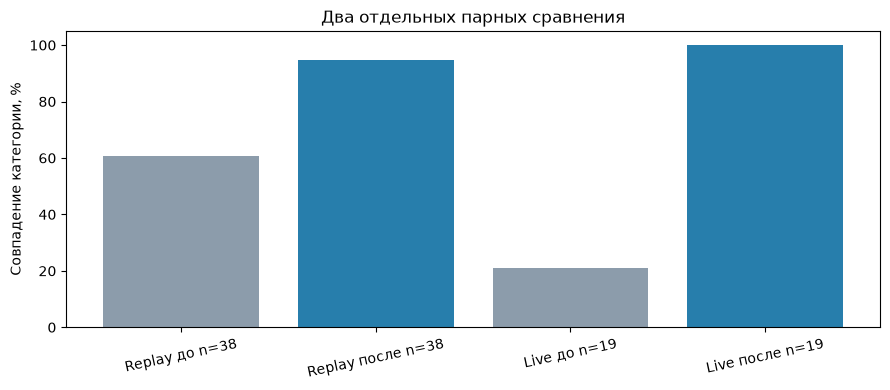

In [6]:
import matplotlib.pyplot as plt
plt.rcParams['font.family']='DejaVu Sans'
fig,ax=plt.subplots(figsize=(9,4))
o=r['replay_suites']['legacy-q015'];n=r['live_paired_suites']['legacy-q015']
labels=['Replay до n=38','Replay после n=38','Live до n='+str(n['before']['observed']),'Live после n='+str(n['after']['observed'])]
values=[o['before']['category_accuracy']['value'],o['after']['category_accuracy']['value'],n['before']['category_accuracy']['value'],n['after']['category_accuracy']['value']]
ax.bar(labels,[100*v for v in values],color=['#8c9cab','#277eac','#8c9cab','#277eac'])
ax.set_ylim(0,105);ax.set_ylabel('Совпадение категории, %');ax.set_title('Два отдельных парных сравнения');plt.xticks(rotation=12);plt.tight_layout();plt.show()

In [7]:
budget=read(EXP/'evidence/budget.json')
print(json.dumps(budget,ensure_ascii=False,indent=2))
from decimal import Decimal
assert Decimal(budget['new_accounted_rub'])<=10
assert budget['technical_reserved']<=20000000
for suite,value in r['live_paired_suites'].items():
 print(suite,'usage',value['after']['tokens'],'latency',value['after']['latency'])

{
  "new_allowance_rub": 10,
  "new_confirmed_rub": "2.185840",
  "new_unknown_reserve_rub": "1.777152",
  "new_accounted_rub": "3.962992",
  "previous_accounted_rub": "23.261663",
  "cumulative_accounted_rub": "27.224655",
  "previous_unknown_reserve_rub": "12.440064",
  "technical_previous": 12667113,
  "technical_new": 745998,
  "technical_cap": 20000000,
  "technical_reserved": 13413111,
  "phases": 2
}
current-policy-reviewed usage {'input': 5517, 'output': 877, 'reasoning': 0} latency {'n': 1, 'p50_ms': 10884.071, 'p95_ms': 10884.071, 'scope': 'Actual local queue/worker/API wall time; pacing before enqueue excluded'}
legacy-q015 usage {'input': 84748, 'output': 7619, 'reasoning': 0} latency {'n': 19, 'p50_ms': 14693.353, 'p95_ms': 47214.7561, 'scope': 'Actual local queue/worker/API wall time; pacing before enqueue excluded'}


In [8]:
proof=read(EXP/'evidence/verification.json')
assert not proof['missing']
print('Langfuse:',proof['observed_generations'],'/',proof['expected_generations'])
print('Все новые человеческие оценки остаются отдельным просмотром; старые оценки не перенесены.')

Langfuse: 26 / 26
Все новые человеческие оценки остаются отдельным просмотром; старые оценки не перенесены.


## Интерпретация
Первое сравнение измеряет изменение кода на фиксированных настоящих генерациях. Второе проверяет новые промпты в составе каскада на известном адресном наборе. Исходные эталоны сохранены. Финансовый резерв отделён от подтверждённых списаний. История полного финального прогона 19.11 сохранена в `lab5-final-20261119.md`.